In [ ]:
import sys; sys.path.append("../src")
import pandas as pd
from data_utils import *
 
df, df_boxes = scan_dataset("../data")
print(len(df), "images,", len(df_boxes), "boxes")

5249 images, 5871 boxes


folder      Train  Val
label                 
Glioma       1153  136
Meningioma   1449  140
No Tumor      711  100
Pituitary    1424  136


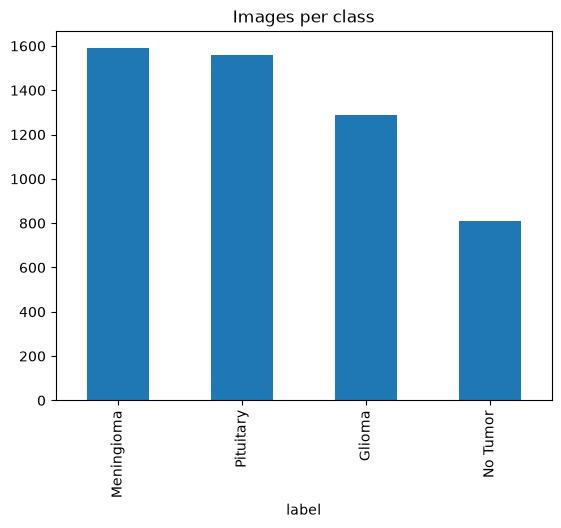

In [2]:
# 2. Class distribution (per original folder)
print(pd.crosstab(df.label, df.folder))
df.label.value_counts().plot(kind="bar", title="Images per class");

In [3]:
# 3. Problems: corrupted files, missing labels, bad boxes, class IDs, duplicates
print("Corrupted:", df.corrupted.sum())
print("Images without label file:", (~df.has_label).sum())
print("Images with bad boxes or class IDs:", (df.n_bad_boxes > 0).sum())
print("Images with class-ID mismatch:", (df.n_class_mismatch > 0).sum())
print("Mismatched annotation rows:", df.n_class_mismatch.sum())
print("Duplicate images:", df.duplicated("md5").sum())
print(df.groupby("label").n_boxes.describe())          # check No Tumor: 0 boxes?
print(df.groupby(["width", "height"]).size().nlargest(5))
print(df["mode"].value_counts())

Corrupted: 0
Images without label file: 2
Images with bad boxes or class IDs: 272
Images with class-ID mismatch: 272
Mismatched annotation rows: 279
Duplicate images: 1336
             count      mean       std  min  25%  50%  75%  max
label                                                          
Glioma      1289.0  1.293251  0.566365  0.0  1.0  1.0  1.0  4.0
Meningioma  1589.0  1.089364  0.322645  1.0  1.0  1.0  1.0  5.0
No Tumor     811.0  0.997534  0.049629  0.0  1.0  1.0  1.0  1.0
Pituitary   1560.0  1.066667  0.254613  1.0  1.0  1.0  1.0  3.0
width  height
512    512       4206
225    225        119
630    630         66
442    442         42
236    236         33
dtype: int64
mode
RGB     4247
L        998
RGBA       3
P          1
Name: count, dtype: int64


In [4]:
# 4. Bounding box format and class consistency check
print("Expected class IDs:", CLASS_TO_ID)
print(df_boxes.groupby(["label", "class_id"]).size())
print("Class-ID mismatches by folder:")
print(df_boxes[~df_boxes.class_matches_folder].groupby("label").size())
print(df_boxes[["xc", "yc", "w", "h"]].describe().loc[["min", "max"]])

Expected class IDs: {'Glioma': 0, 'Meningioma': 1, 'No Tumor': 2, 'Pituitary': 3}
label       class_id
Glioma      0           1500
            1              3
            3            164
Meningioma  0              2
            1           1620
            3            109
No Tumor    2            809
Pituitary   1              1
            3           1663
dtype: int64
Class-ID mismatches by folder:
label
Glioma        167
Meningioma    111
Pituitary       1
dtype: int64
           xc        yc         w         h
min  0.155273  0.123047  0.019531  0.017578
max  0.843750  0.800000  0.996063  0.997984


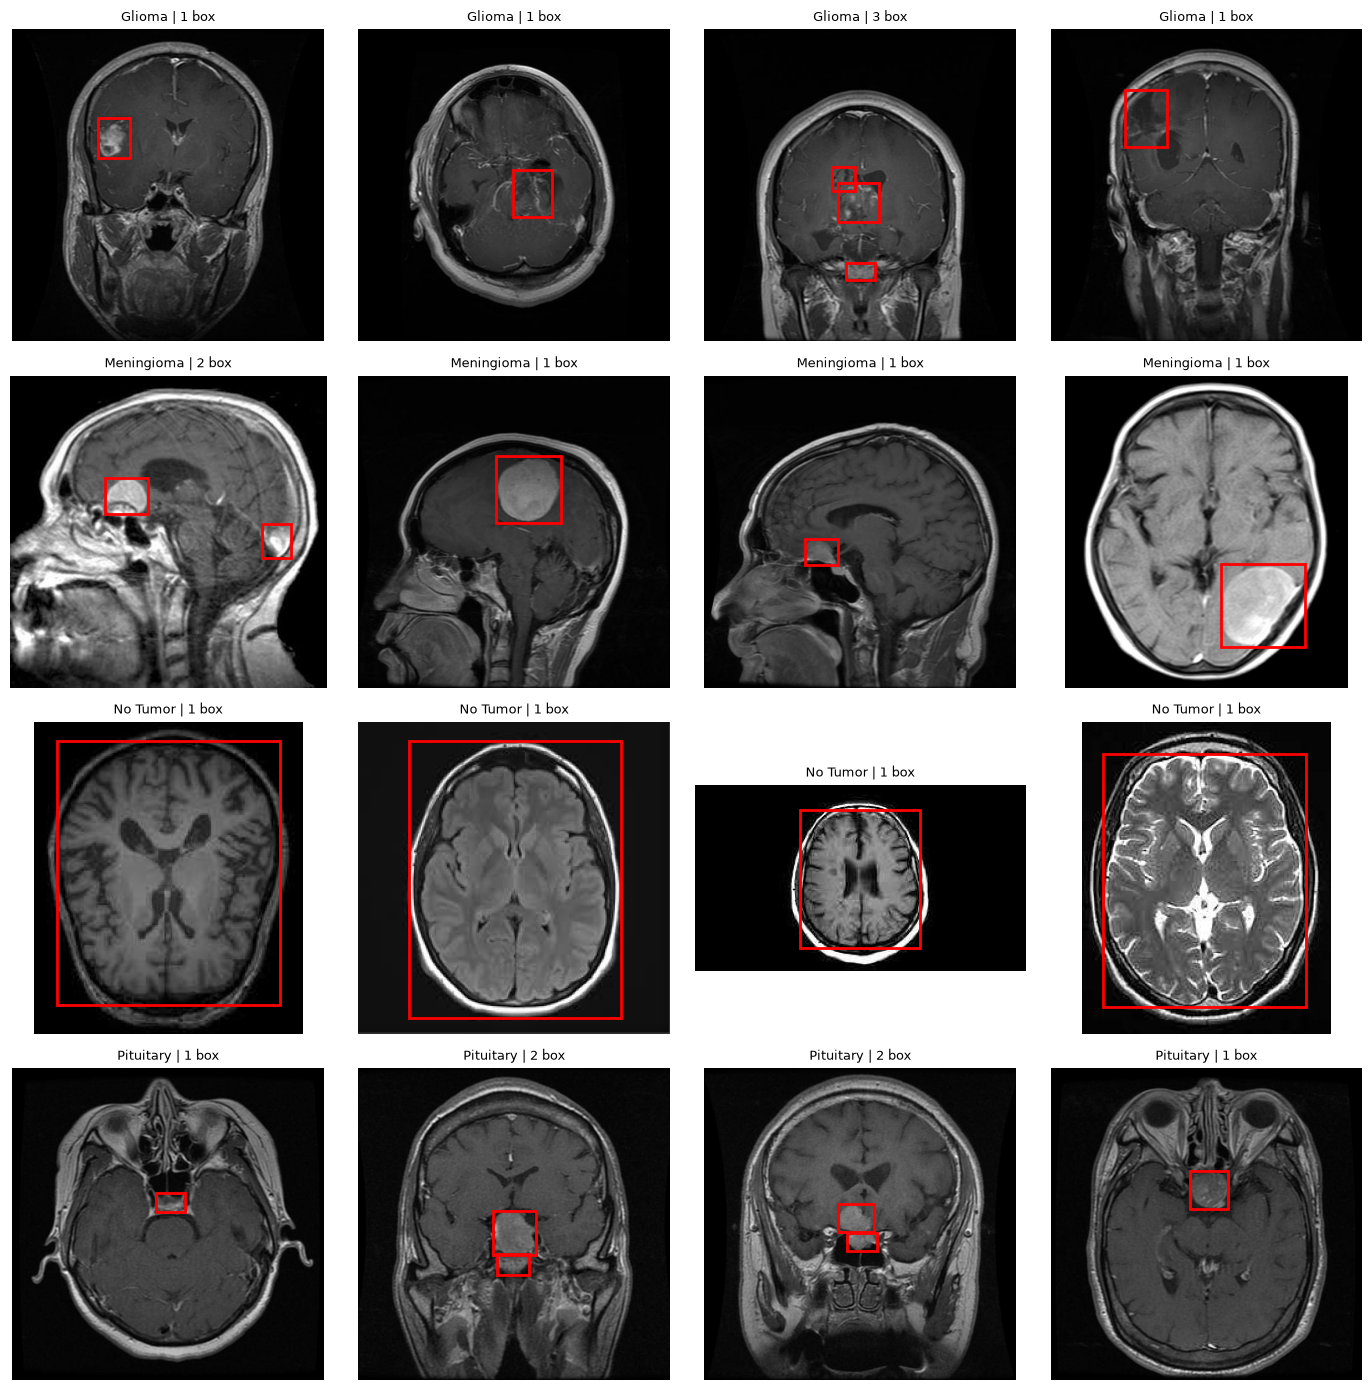

In [5]:
# 5. Visualize
show_samples(df, df_boxes, n=4)

In [6]:
# 6. Split original Train into folders; keep original Val unchanged.
split_df = clean_and_split(df, output_root="../data/split", test_size=0.20)

print(split_df.split.value_counts())
print(pd.crosstab(split_df.label, split_df.split, normalize="columns").round(2))
assert split_df.md5.is_unique and split_df.path.is_unique
val_hashes = set(df.loc[df.folder == "Val", "md5"].dropna())
assert not (set(split_df.md5) & val_hashes), "An identical image appears in Val and the new Train/Test folders"
print("No exact-image leakage: OK")
print("Created folders: ../data/split/Train and ../data/split/Test")
print("Original ../data/Val folder was not changed.")

split
Train    2583
Test      646
Name: count, dtype: int64
split       Test  Train
label                  
Glioma      0.28   0.29
Meningioma  0.28   0.28
No Tumor    0.16   0.16
Pituitary   0.28   0.28
No exact-image leakage: OK
Created folders: ../data/split/Train and ../data/split/Test
Original ../data/Val folder was not changed.
